In [1]:
import numpy as np
import matplotlib.pyplot as plt

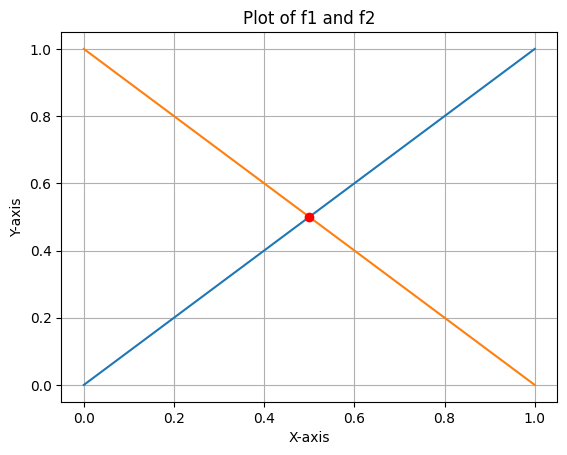

In [42]:
x = np.linspace(0, 1, 101)
f1 = x
f2 = 1-x
index = np.argwhere(f2 == f1)[0][0]
x_intersection = x[index] 
# y = np.tan(x)
# plt.plot(x, y)
plt.plot(x, f1)
plt.plot(x, f2)
plt.plot(x_intersection, f1[index], 'ro')  # Mark the intersection point
plt.title('Plot of f1 and f2')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.grid()

In [31]:
n = 1001
xmin = -0.2 * 10**(-9)  # m
xmax = 0.2 * 10**(-9)  # m
delx = (xmax - xmin)/(n-1)
x = np.linspace(xmin, xmax, n)
h_bar = 1.054 * 10**(-34)  # J/s
m = 9.1 * 10**(-31)  #kg
e = 1.6 * 10**(-19)  #C
c = (h_bar**2)/(2*m*e*delx**2)
print(c)
a = 0.1 *10**(-9)    # Well width in m

238434.9244505493


In [32]:
V0 = 100 # eV
z0 = a*np.sqrt((2*m*e*V0)/h_bar**2)
print(z0)

5.11982450217535


In [49]:
z = np.linspace(0,12, 1001)
f1 = np.tan(z)
f2 = np.sqrt((z0/z) -1)
f3 = -(1/np.tan(z))  # cotangent function

print("f2.size :",f2.size, "f3 size: ", f3.size)

f2.size : 1001 f3 size:  1001


/tmp/ipykernel_3933/1365392666.py:3: RuntimeWarning: divide by zero encountered in divide
  f2 = np.sqrt((z0/z) -1)
/tmp/ipykernel_3933/1365392666.py:3: RuntimeWarning: invalid value encountered in sqrt
  f2 = np.sqrt((z0/z) -1)
/tmp/ipykernel_3933/1365392666.py:4: RuntimeWarning: divide by zero encountered in divide
  f3 = -(1/np.tan(z))  # cotangent function


In [ ]:
index = np.argwhere(f2 == f1)[0][0]
x1 = z[index]
y1 = f1[index]

index2 = np.argwhere(f2 == f3)[0][0]
x2 = z[index2]
y2 = f1[index2]

IndexError: index 0 is out of bounds for axis 0 with size 0

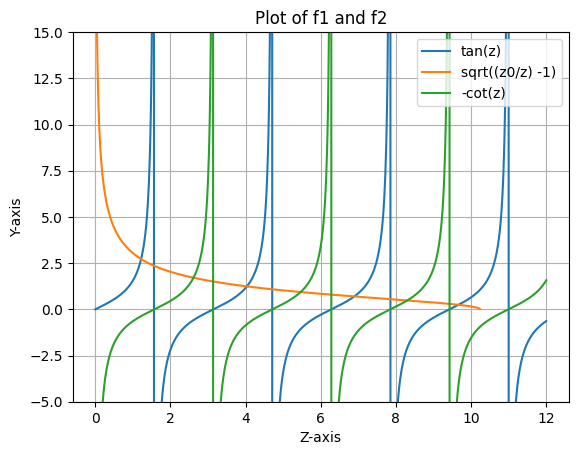

In [ ]:
plt.plot(z, f1, label="tan(z)")
plt.plot(z, f2, label="sqrt((z0/z) -1)")
plt.plot(z, f3, label="-cot(z)") 
plt.plot(x, y, 'ro', label="Intersection f1 and f2")
plt.plot(x2, y2, 'go', label="Intersection f1 and f3")
plt.title('Plot of f1 and f2')
plt.xlabel('Z-axis')
plt.ylabel('Y-axis')
plt.ylim(-5, 15)
plt.grid()
plt.legend()

# Preamble

In [2]:
n = 1001

m = 9.1 *10**(-31)          # mass of electron in kg
h_bar = 1.054 * 10**(-34)  # Planck's constant in J*s
e = 1.6 * 10**(-19)        # elementary charge in C
Z = 1                      # Atomic number for hydrogen
k = 8.99 * 10**9           # Coulomb's constant (1/4 pi epsilon_0) in N*m^2/C^2
a0 = 5.29 * 10**(-9)        # Bohr radius in m
E0 = -13.6   # eV, ground state energy of hydrogen

r_min = 10**(-15)
r_max = 10**(-9)
r = np.linspace(r_min, r_max, n)
delta_r = r[1] - r[0]

c = (h_bar**2) / (2*m *e*delta_r**2)
print(c)

a = np.array([0.3, 0.5, 0.7])  # in nm
a = a* 10**(-9)

38149.664211378156


# Hamiltonian
Screened coulomb $V_S(r) = V_C(r)\exp(\frac{-r}{a})$

In [ ]:
v_c = -k*Z*e/r  # Coulomb potential
v_s = np.zeros((len(r), len(a)))  # rows for r, columns for a

ke = (-c) * (np.eye(n-2, k=1) - 2*np.eye(n-2) + np.eye(n-2, k=-1))

# Maximum possible number of eigenstates
max_states = n-2

# Storage
psi = np.full((n-2, len(a), max_states), np.nan)
energy = np.full((len(a), max_states), np.nan)  # 

# Number of bound states for each screening length
bound_count = np.zeros(len(a), dtype=int)

for i in range(len(a)):    # Loop over screening lengths
    v_s[:, i] = v_c * np.exp(-r/a[i])
    pe = np.diag(v_s[1:-1, i])  # Potential energy matrix for the current screening length
    Hamiltonian = ke + pe
    eig_val, eig_vec = np.linalg.eigh(Hamiltonian)

    # Identify bound states
    count = np.sum(eig_val < 0)
    bound_count[i] = count

    # Store only bound-state energies
    energy[i, :count] = eig_val[:count]

    # NORMALISE and store only bound-state wavefunctions
    for j in range(count):
        norm = np.sqrt(np.trapezoid(eig_vec[:, j]**2, r[1:-1]))
        psi[:, i, j] = eig_vec[:, j]/norm           # psi[r_index, screening_index, state_index]
        
    d = Z*a[i]/a0
    print("\na =", a[i], "m, ZD/a0 =", d)
    print("Number of bound states:", count)
    print("Bound energies:", eig_val[:count], "eV")
    print("Energy ratios:", eig_val[:count]/E0)



a = 3e-10 m, ZD/a0 = 0.05671077504725897
Number of bound states: 2
Bound energies: [-9.33630798 -0.47590984] eV
Energy ratios: [0.68649323 0.03499337]

a = 5e-10 m, ZD/a0 = 0.0945179584120983
Number of bound states: 2
Bound energies: [-10.89413664  -1.2625173 ] eV
Energy ratios: [0.80103946 0.09283215]

a = 7e-10 m, ZD/a0 = 0.1323251417769376
Number of bound states: 2
Bound energies: [-11.61280641  -1.73583728] eV
Energy ratios: [0.85388282 0.12763509]


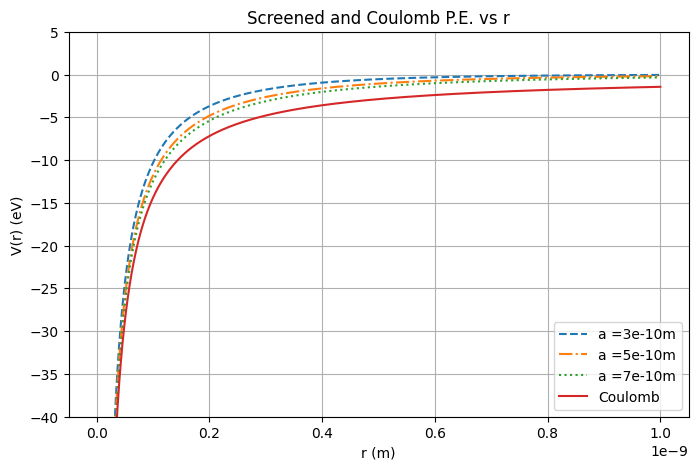

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(r, v_s[:, 0], label= f"a ={a[0]}m", ls='--')
plt.plot(r, v_s[:, 1], label= f"a ={a[1]}m", ls='-.')
plt.plot(r, v_s[:, 2], label= f"a ={a[2]}m", ls=':')
plt.plot(r, v_c, label= "Coulomb")
plt.title(f"Screened and Coulomb P.E. vs r")
plt.xlabel('r (m)')
plt.ylabel("V(r) (eV)")
plt.ylim(-40, 5)
plt.legend()
plt.grid()
plt.show()

### (Coulomb potential calculations)

In [5]:
r_new = r[1:-1]  # Exclude the first and last points to avoid singularity and boundary issues

pe_c = np.diag(v_c[1:-1])
H_c = ke + pe_c
energy_c, psi_c = np.linalg.eigh(H_c)

# Normalise GND state & 1st excited state
norm = np.sqrt(np.trapezoid(psi_c[:,0]**2, r_new))
psi_coulomb_st0 = psi_c[:,0]/norm
norm = np.sqrt(np.trapezoid(psi_c[:,1]**2, r_new))
psi_coulomb_st1 = psi_c[:,1]/norm

# Plots, ground state and 1st excited state

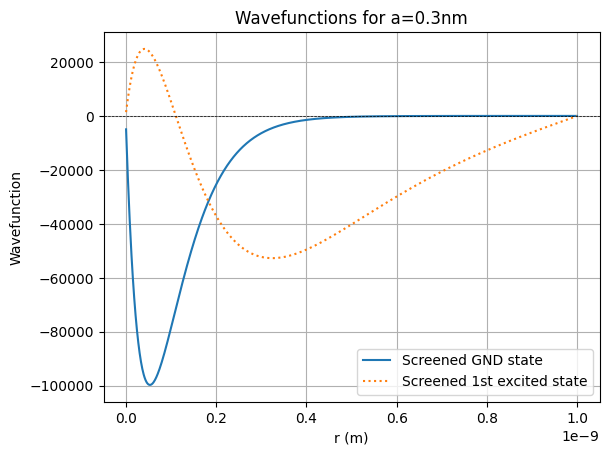

In [6]:
plt.plot(r_new, psi[:,0,0], label="Screened GND state ")
plt.plot(r_new, psi[:,0,1], label="Screened 1st excited state", ls=':')

plt.title("Wavefunctions for a=0.3nm")
plt.xlabel("r (m)")
plt.ylabel("Wavefunction")
plt.axhline(0, color='black', lw=0.5, ls='--')
plt.legend(loc='lower right')
plt.grid()
plt.show()

## Plots, 

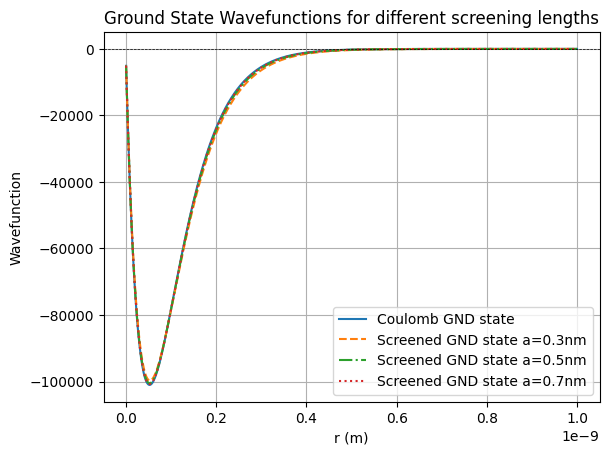

In [9]:
plt.plot(r_new, psi_coulomb_st0, label="Coulomb GND state")
plt.plot(r_new, psi[:,0,0], label="Screened GND state a=0.3nm", ls='--')
plt.plot(r_new, psi[:,1,0], label="Screened GND state a=0.5nm", ls='-.')
plt.plot(r_new, psi[:,2,0], label="Screened GND state a=0.7nm", ls=':')
plt.title("Ground State Wavefunctions for different screening lengths")
plt.xlabel("r (m)")
plt.ylabel("Wavefunction")
plt.axhline(0, color='black', lw=0.5, ls='--')
plt.legend(loc='lower right')
plt.grid()
plt.show()

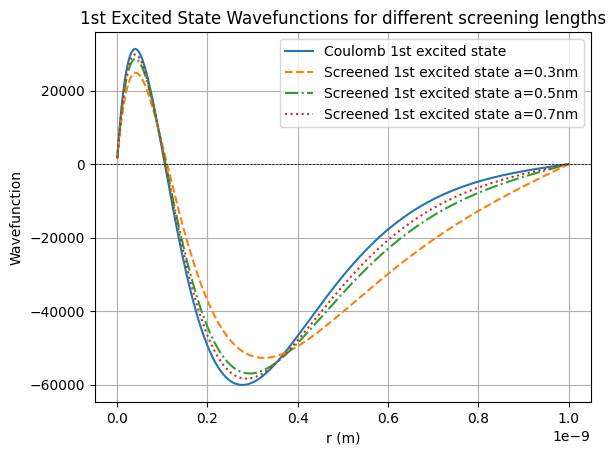

In [10]:
plt.plot(r_new, psi_coulomb_st1, label="Coulomb 1st excited state")
plt.plot(r_new, psi[:,0,1], label="Screened 1st excited state a=0.3nm", ls='--')
plt.plot(r_new, psi[:,1,1], label="Screened 1st excited state a=0.5nm", ls='-.')
plt.plot(r_new, psi[:,2,1], label="Screened 1st excited state a=0.7nm", ls=':')
plt.title("1st Excited State Wavefunctions for different screening lengths")
plt.xlabel("r (m)")
plt.ylabel("Wavefunction")
plt.axhline(0, color='black', lw=0.5, ls='--')
plt.legend(loc='upper right')
plt.grid()
plt.show()

## Expectation
$\sigma_p = <p^2> - <p>^2$ and $\hat{p} = -i \bar{h}\frac{\delta}{x}$

In [11]:
# Latest
count = len(a)

# Allocate expectation-value arrays
exp_x = np.full((count, max_states), np.nan)
exp_x2 = np.full((count, max_states), np.nan)
exp_v = np.full((count, max_states), np.nan)

exp_p = np.full((count, max_states), np.nan)
exp_p2 = np.full((count, max_states), np.nan)
exp_ke = np.full((count, max_states), np.nan)

sigma_x = np.full((count, max_states), np.nan)
sigma_p = np.full((count, max_states), np.nan)
sigma_xp = np.full((count, max_states), np.nan)


# First derivative
diff_psi = (psi[1:, :, :] - psi[:-1, :, :])/delta_r

# Midpoint coordinates and wavefunctions
xmid = (r_new[1:] + r_new[:-1])/2
psi_mid = (psi[1:, :, :] + psi[:-1, :, :])/2

# Second derivative
diff2_psi = (diff_psi[1:, :, :] - diff_psi[:-1, :, :])/delta_r
psi_mid2 = psi[1:-1, :, :]

xmid2 = r_new[1:-1]

In [13]:
num_screenings = len(a)
print("Calculating expectation values for bound states:")
for i in range(num_screenings):

    print(f"\nScreening length a[{i}] = {a[i]}m")

    # Only iterate over the bound states that actually exist
    for j in range(bound_count[i]):
        print("\nState j = ",j+1)

        # Extract the particular wavefunction
        psi_ij = psi[:, i, j]
        # Potential corresponding to this screening length
        V_i = v_s[1:-1, i]

        # <r> = integral of r * |psi|^2
        yp = r_new * psi_ij**2
        exp_x[i, j] = np.trapezoid(yp, r_new)

        # <r^2>
        yp2 = r_new**2 * psi_ij**2
        exp_x2[i, j] = np.trapezoid(yp2, r_new)

        # <V>
        yp3 = V_i * psi_ij**2
        exp_v[i, j] = np.trapezoid(yp3, r_new)

        print("<r> =", exp_x[i, j])
        print("<r^2> =", exp_x2[i, j])
        print("<V> =", exp_v[i, j])

        # <p> = -i*h_bar * integral(psi* dpsi/dr)
        yp4 = psi_mid[:, i, j] * diff_psi[:, i, j]

        exp_p[i, j] = h_bar * np.trapezoid(yp4, xmid)

        print("<p> =", -1j * exp_p[i, j])

        # <p^2> = -h_bar^2 * integral(psi* d2psi/dr2)
        yp5 = psi_mid2[:, i, j] * diff2_psi[:, i, j]

        exp_p2[i, j] = (-h_bar**2 * np.trapezoid(yp5, xmid2))
        print("<p^2> =", exp_p2[i, j])
        # <KE> = <p^2>/(2m), converted from J to eV
        exp_ke[i, j] = exp_p2[i, j]/(2*m*e)

        print("<KE> =", exp_ke[i, j], "eV")

        # Total energy
        E_total = exp_ke[i, j] + exp_v[i, j]

        print("<KE> + <V> =", E_total, "eV")
        print("Eigenvalue =", energy[i, j], "eV")

        # Position uncertainty
        var_x = exp_x2[i, j] - exp_x[i, j]**2
        sigma_x[i, j] = np.sqrt(max(var_x, 0))

        # Momentum uncertainty
        var_p = exp_p2[i, j] - (-(exp_p[i, j])**2 ) # <p>^2 = ex_p[i, j]**2 * (-1j)^2 = -ex_p[i, j]**2
        sigma_p[i, j] = np.sqrt(max(var_p, 0))

        sigma_xp[i, j] = sigma_x[i, j] * sigma_p[i, j]

        print("Sigma_x =", sigma_x[i, j])
        print("Sigma_p =", sigma_p[i, j])
        print("Sigma_x * Sigma_p /(h'/2)=", sigma_xp[i, j]*2/h_bar)

Calculating expectation values for bound states:

Screening length a[0] = 3e-10m

State j =  1
<r> = 8.166709680046412e-11
<r^2> = 8.94518228079162e-21
<V> = -22.34759749332809
<p> = 3.168635513144754e-27j
<p^2> = 3.773957462326844e-48
<KE> = 12.960018757990536 eV
<KE> + <V> = -9.387578735337556 eV
Eigenvalue = -9.336307981633771 eV
Sigma_x = 4.7703957707670796e-11
Sigma_p = 1.942670199127443e-24
Sigma_x * Sigma_p /(h'/2)= 1.7585020307234904

State j =  2
<r> = 3.8896155782327886e-10
<r^2> = 1.7607652664066317e-19
<V> = -2.578225452475096
<p> = 2.500867823779494e-28j
<p^2> = 6.110014362645035e-49
<KE> = 2.0982192179412893 eV
<KE> + <V> = -0.48000623453380653 eV
Eigenvalue = -0.4759098398702854 eV
Sigma_x = 1.5743390097546098e-10
Sigma_p = 7.816658485618405e-25
Sigma_x * Sigma_p /(h'/2)= 2.3351177191344306

Screening length a[1] = 5e-10m

State j =  1
<r> = 8.037016812621918e-11
<r^2> = 8.632263063157307e-21
<V> = -24.226944641148144
<p> = 3.248271202388518e-27j
<p^2> = 3.86720210013830